In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Using a seed ensures everyone generates the same sample
rng = np.random.default_rng(42)

stores = ["Nairobi", "Thika", "Nyali", "Nakuru"]
products = {
    "Staples": 240,
    "Fresh Produce": 180,
    "Dairy & Eggs": 360,
    "Beverages": 150,
    "Personal Care": 420
}

rows = []
for i in range(100):
    category = rng.choice(list(products), p=[0.30, 0.25, 0.20, 0.15, 0.10])
    quantity = int(rng.integers(1, 6))
    price = round(products[category] * rng.uniform(0.85, 1.15), 2)
    promotion = bool(rng.choice([True, False], p=[0.28, 0.72]))
    discount = 0.10 if promotion else 0
    sale = round(quantity * price * (1 - discount), 2)

    rows.append({
        "transaction_id": f"TX{i+1:03d}",
        "date": pd.Timestamp("2025-01-01") + pd.Timedelta(days=int(rng.integers(0, 365))),
        "customer_id": f"C{int(rng.integers(1, 36)):03d}",
        "store": rng.choice(stores, p=[0.40, 0.25, 0.20, 0.15]),
        "category": category,
        "quantity": quantity,
        "unit_price_kes": price,
        "promotion": promotion,
        "payment_method": rng.choice(["M-Pesa", "Cash", "Card"], p=[0.62, 0.25, 0.13]),
        "revenue_kes": sale
    })

df = pd.DataFrame(rows).sort_values("date").reset_index(drop=True)
display(df.head())
print("Dataset size:", df.shape)

,transaction_id,date,customer_id,store,category,quantity,unit_price_kes,promotion,payment_method,revenue_kes
0,TX083,2025-01-04,C017,Nairobi,Dairy & Eggs,2,328.58,False,Cash,657.16
1,TX062,2025-01-05,C011,Nakuru,Staples,1,237.02,False,Cash,237.02
2,TX030,2025-01-12,C005,Nyali,Staples,2,271.45,True,M-Pesa,488.61
3,TX005,2025-01-16,C033,Nakuru,Fresh Produce,3,161.33,False,M-Pesa,483.99
4,TX048,2025-01-23,C005,Thika,Fresh Produce,3,187.54,True,M-Pesa,506.36


Dataset size: (100, 10)


In [2]:
print("Missing values:", df.isna().sum().sum())
print("Duplicate IDs:", df["transaction_id"].duplicated().sum())
print("Invalid quantities:", (df["quantity"] <= 0).sum())
print("Negative sales:", (df["revenue_kes"] < 0).sum())

Missing values: 0
Duplicate IDs: 0
Invalid quantities: 0
Negative sales: 0


## Key Business Numbers

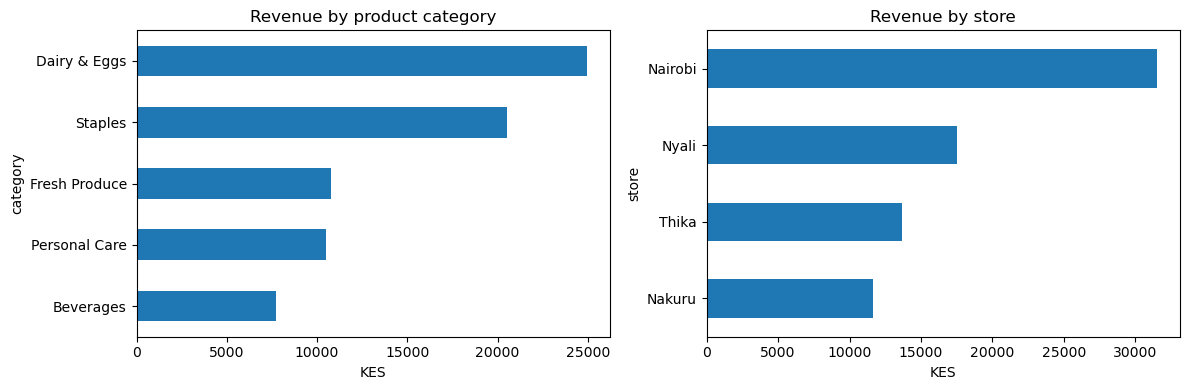

In [3]:
category_sales = df.groupby("category")["revenue_kes"].sum().sort_values()
store_sales = df.groupby("store")["revenue_kes"].sum().sort_values()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
category_sales.plot(kind="barh", ax=axes[0], title="Revenue by product category")
store_sales.plot(kind="barh", ax=axes[1], title="Revenue by store")
axes[0].set_xlabel("KES")
axes[1].set_xlabel("KES")
plt.tight_layout()
plt.show()

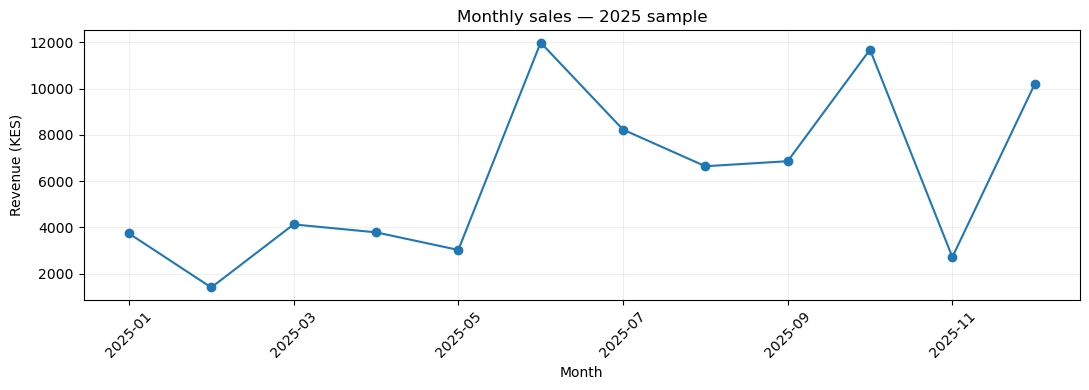

Payment method counts:


,transactions
payment_method,
M-Pesa,57
Cash,30
Card,13


In [4]:
df["month"] = df["date"].dt.to_period("M").astype(str)
monthly_sales = df.groupby("month")["revenue_kes"].sum()

plt.figure(figsize=(11, 4))
monthly_sales.plot(marker="o")
plt.title("Monthly sales — 2025 sample")
plt.ylabel("Revenue (KES)")
plt.xlabel("Month")
plt.xticks(rotation=45)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print("Payment method counts:")
display(df["payment_method"].value_counts().rename("transactions").to_frame())

## Are Promotional Purchases Larger

In [5]:
comparison = df.groupby("promotion")["revenue_kes"].agg(["count", "mean"])
comparison.index = ["Without promotion", "With promotion"]
display(comparison.round(2))

,count,mean
Without promotion,72,768.43
With promotion,28,681.92


## Customer Activity

In [6]:
customers = df.groupby("customer_id").agg(
    orders=("transaction_id", "count"),
    spend_kes=("revenue_kes", "sum"),
    last_visit=("date", "max")
)

customers["segment"] = np.where(customers["orders"] >= 4, "Frequent", "Occasional")

print("Customers by segment:")
display(customers["segment"].value_counts().to_frame("customers"))

print("Top 5 customers by spend:")
display(customers.sort_values("spend_kes", ascending=False).head(5))

Customers by segment:


,customers
segment,
Occasional,21
Frequent,13


Top 5 customers by spend:


,orders,spend_kes,last_visit,segment
customer_id,,,,
C004,5,5880.44,2025-12-17,Frequent
C025,4,4680.06,2025-10-09,Frequent
C023,4,4564.91,2025-08-15,Frequent
C035,4,4315.12,2025-10-20,Frequent
C015,4,3653.78,2025-10-14,Frequent


## Findings

In [7]:
top_category = category_sales.idxmax()
top_store = store_sales.idxmax()
repeat_count = (customers["orders"] >= 2).sum()

print(f"1. {top_category} contributes the most sales in this sample.")
print(f"2. {top_store} is the highest-revenue store in this sample.")
print(f"3. {repeat_count} customers made more than one purchase.")
print("4. Use these findings to decide which questions to investigate with a larger real dataset.")

1. Dairy & Eggs contributes the most sales in this sample.
2. Nairobi is the highest-revenue store in this sample.
3. 28 customers made more than one purchase.
4. Use these findings to decide which questions to investigate with a larger real dataset.


In [9]:
# Create the data folder
data_folder = Path("data")
data_folder.mkdir(exist_ok=True)

# Save the 100 retail transactions
df.to_csv("data/retail_transactions.csv", index=False)

# Save revenue by product category
category_summary = df.groupby("category")["revenue_kes"].sum()
category_summary.to_csv("data/category_revenue.csv")

# Save revenue by store
store_summary = df.groupby("store")["revenue_kes"].sum()
store_summary.to_csv("data/store_revenue.csv")

print("Datasets saved successfully!")
print("Total transactions:", len(df))

Datasets saved successfully!
Total transactions: 100
